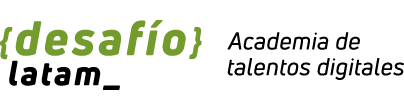

# <center><font color = 'green'>Guía - Modelos de ensamble (parte II)

# **Modelos de Ensamble**

Los modelos de ensamble son técnicas que combinan múltiples modelos para mejorar la precisión y la robustez de las predicciones. Se pueden clasificar principalmente en dos categorías: ensambles paralelos y secuenciales. Aquí te explico cada uno y sus diferencias:

### Modelos de Ensamble Paralelos

1. **Definición**: En los ensambles paralelos, múltiples modelos se entrenan de manera independiente y simultánea en el mismo conjunto de datos.

2. **Ejemplos**: Algunos ejemplos son el **Bagging** (como Random Forest) y el **Voting Classifier**.

3. **Funcionamiento**: Cada modelo hace una predicción y luego se combinan sus resultados, generalmente a través de promedios (regresión) o votaciones (clasificación).

4. **Ventaja**: Ayuda a reducir la varianza y puede mejorar la estabilidad y la generalización del modelo, ya que los errores de los modelos individuales pueden cancelarse entre sí.

### Modelos de Ensamble Secuenciales

1. **Definición**: En los ensambles secuenciales, los modelos se entrenan uno tras otro. Cada modelo se ajusta en función de los errores de los modelos anteriores.

2. **Ejemplos**: Ejemplos comunes son **AdaBoost** y **Gradient Boosting** (incluyendo XGBoost).

3. **Funcionamiento**: Cada nuevo modelo se centra en corregir los errores del modelo anterior, ajustando los pesos de los ejemplos para que los más difíciles sean más relevantes en la siguiente iteración.

4. **Ventaja**: Esto puede llevar a un modelo más potente y preciso, ya que cada nuevo modelo mejora sobre el anterior, abordando errores específicos.

### Diferencias Clave

- **Independencia**: Los modelos paralelos se entrenan de manera independiente, mientras que los secuenciales dependen de los resultados de los modelos anteriores.
  
- **Reducción de error**: Los ensambles paralelos tienden a reducir la varianza, mientras que los secuenciales pueden abordar tanto la varianza como el sesgo, mejorando la precisión general.

- **Complejidad**: Los modelos secuenciales pueden ser más complejos de implementar y entrenar debido a su naturaleza dependiente.

Ambos enfoques tienen sus propias ventajas y son útiles en diferentes contextos, dependiendo del problema y los datos que se estén utilizando.

# **Modelos de Ensammble secuenciales**

## AdaBoost


AdaBoost, o "Adaptive Boosting", es un algoritmo de aprendizaje automático que combina varios modelos débiles (generalmente árboles de decisión muy simples) para crear un modelo más fuerte. Aquí te lo explico en pasos sencillos:

1. **Modelo débil**: Comienza con un modelo que solo es un poco mejor que el azar (esto se llama modelo débil).

2. **Entrenamiento iterativo**: Entrena el modelo en los datos. Luego, evalúa su desempeño para ver qué ejemplos clasificó incorrectamente.

3. **Ponderación de ejemplos**: Aumenta el peso de los ejemplos que fueron mal clasificados. Esto significa que el siguiente modelo se enfocará más en esos ejemplos difíciles.

4. **Modelo nuevo**: Crea un nuevo modelo débil con los datos ajustados y repite el proceso: evalúa, ajusta los pesos y entrena de nuevo.

5. **Combina modelos**: Después de varias iteraciones, combina todos los modelos débiles en uno solo. Cada modelo tiene un peso en la votación final, basado en su precisión.

6. **Predicción final**: Cuando haces una predicción, cada modelo "vota", y la decisión final se toma en función de esas votaciones.

La clave de AdaBoost es que se adapta a los errores de los modelos anteriores, mejorando la precisión en general. Es muy efectivo para muchos problemas de clasificación.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.datasets import load_breast_cancer


In [57]:
cancer.feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

In [ ]:
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=[cancer.feature_names])
y = pd.Series(data=cancer.target, index=X.index)
X.sample(7)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
87,19.02,24.59,122.00,1076.0,0.09029,0.12060,0.14680,0.08271,0.1953,0.05629,...,24.56,30.41,152.90,1623.0,0.1249,0.3206,0.57550,0.19560,0.3956,0.09288
39,13.48,20.82,88.40,559.2,0.10160,0.12550,0.10630,0.05439,0.1720,0.06419,...,15.53,26.02,107.30,740.4,0.1610,0.4225,0.50300,0.22580,0.2807,0.10710
225,14.34,13.47,92.51,641.2,0.09906,0.07624,0.05724,0.04603,0.2075,0.05448,...,16.77,16.90,110.40,873.2,0.1297,0.1525,0.16320,0.10870,0.3062,0.06072
348,11.47,16.03,73.02,402.7,0.09076,0.05886,0.02587,0.02322,0.1634,0.06372,...,12.51,20.79,79.67,475.8,0.1531,0.1120,0.09823,0.06548,0.2851,0.08763
267,13.59,21.84,87.16,561.0,0.07956,0.08259,0.04072,0.02142,0.1635,0.05859,...,14.80,30.04,97.66,661.5,0.1005,0.1730,0.14530,0.06189,0.2446,0.07024
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.37840,0.19320,0.3063,0.08368
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.53550,0.17410,0.3985,0.12440


In [59]:
y

,0
0,0
1,0
2,0
3,0
4,0
...,...
564,0
565,0
566,0
567,0


In [ ]:
print(X.shape)
X.describe()
X.info

(569, 30)


<bound method DataFrame.info of     mean radius mean texture mean perimeter mean area mean smoothness  \
0         17.99        10.38         122.80    1001.0         0.11840   
1         20.57        17.77         132.90    1326.0         0.08474   
2         19.69        21.25         130.00    1203.0         0.10960   
3         11.42        20.38          77.58     386.1         0.14250   
4         20.29        14.34         135.10    1297.0         0.10030   
..          ...          ...            ...       ...             ...   
564       21.56        22.39         142.00    1479.0         0.11100   
565       20.13        28.25         131.20    1261.0         0.09780   
566       16.60        28.08         108.30     858.1         0.08455   
567       20.60        29.33         140.10    1265.0         0.11780   
568        7.76        24.54          47.92     181.0         0.05263   

    mean compactness mean concavity mean concave points mean symmetry  \
0            0.27760        0.30010             0.14710        0.2419   
1            0.07864        0.08690             0.07017        0.1812   
2            0.15990        0.19740             0.12790        0.2069   
3            0.28390        0.24140             0.10520        0.2597   
4            0.13280        0.19800             0.10430        0.1809   
..               ...            ...                 ...           ...   
564          0.11590        0.24390             0.13890        0.1726   
565          0.10340        0.14400             0.09791        0.1752   
566          0.10230        0.09251             0.05302        0.1590   
567          0.27700        0.35140             0.15200        0.2397   
568          0.04362        0.00000             0.00000        0.1587   

    mean fractal dimension  ... worst radius worst texture worst perimeter  \
0                  0.07871  ...       25.380         17.33          184.60   
1                  0.05667  ...       24.990         23.41          158.80   
2                  0.05999  ...       23.570         25.53          152.50   
3                  0.09744  ...       14.910         26.50           98.87   
4                  0.05883  ...       22.540         16.67          152.20   
..                     ...  ...          ...           ...             ...   
564                0.05623  ...       25.450         26.40          166.10   
565                0.05533  ...       23.690         38.25          155.00   
566                0.05648  ...       18.980         34.12          126.70   
567                0.07016  ...       25.740         39.42          184.60   
568                0.05884  ...        9.456         30.37           59.16   

    worst area worst smoothness worst compactness worst concavity  \
0       2019.0          0.16220           0.66560          0.7119   
1       1956.0          0.12380           0.18660          0.2416   
2       1709.0          0.14440           0.42450          0.4504   
3        567.7          0.20980           0.86630          0.6869   
4       1575.0          0.13740           0.20500          0.4000   
..         ...              ...               ...             ...   
564     2027.0          0.14100           0.21130          0.4107   
565     1731.0          0.11660           0.19220          0.3215   
566     1124.0          0.11390           0.30940          0.3403   
567     1821.0          0.16500           0.86810          0.9387   
568      268.6          0.08996           0.06444          0.0000   

    worst concave points worst symmetry worst fractal dimension  
0                 0.2654         0.4601                 0.11890  
1                 0.1860         0.2750                 0.08902  
2                 0.2430         0.3613                 0.08758  
3                 0.2575         0.6638                 0.17300  
4                 0.1625         0.2364                 0.07678  
..                   ...            ...             

Dividiremos ahora los datos para entrenamiento y test, y con ello crear el modelo de ensamble AdaBoost con un learner base árbol de decisión de profundidad dos. Luego se entrena con los datos de entrenamiento y es sometido a predicción con el segmento de test

In [ ]:
# Dividir los datos en entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.33, random_state=23)


In [ ]:
# aprendiz débil para el ensamble
learner_base = DecisionTreeClassifier(max_depth=2)

# creamos el modelo de ensamble AdaBoost con 25 iteraciones
aboost_m1 = AdaBoostClassifier(estimator=learner_base, n_estimators=25, learning_rate=.75)

# entrenamos el modelo con los datos de entrenamiento
aboost_m1.fit(X_train, y_train)

# obtener predicciones para el conjunto de test
yhat_test = aboost_m1.predict(X_test)




/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


0.05319148936170215


In [60]:
yhat_test

array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1,
       0, 0, 1])

In [63]:
y_test

,0
1,0
6,0
11,0
17,0
19,1
...,...
555,1
559,1
564,0
567,0


In [62]:
# se calcula el error
err = 1 - accuracy_score(y_test, yhat_test)
print(err)

0.07964601769911506


Se muestran ahora los resultados del clasificador en el conjunto de entrenamiento

In [ ]:
yhat_train = aboost_m1.predict(X_train)
err = 1 - accuracy_score(y_train, yhat_train)
print(err)

print(classification_report(y_train, yhat_train))


0.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       139
           1       1.00      1.00      1.00       242

    accuracy                           1.00       381
   macro avg       1.00      1.00      1.00       381
weighted avg       1.00      1.00      1.00       381



Se muestran los resultados del clasificador en el conjunto de test

In [ ]:
print(classification_report(y_test, yhat_test))

              precision    recall  f1-score   support

           0       0.97      0.89      0.93        73
           1       0.93      0.98      0.96       115

    accuracy                           0.95       188
   macro avg       0.95      0.94      0.94       188
weighted avg       0.95      0.95      0.95       188



Podemos destacar que en el conjunto de entrenamiento se logran clasificaciones ideales, lo cual hace sospechar de overfitting. Sin embargo, en el segmento de test tenemos un 95% en exactitud y un f1-score promedio ponderado de 95%.

###Impacto en el error por la cantidad de estimadores

Para revisar la incidencia que tiene la cantidad de aprendices débiles en el error aplicado a los datos de train y test, entrenamos 10 AdaBoost con árboles de decisión de profundidad uno, y aplicamos validación cruzada de manera estratificada para mantener las proporciones de las clases, con 5 fold cada vez.


In [ ]:
from sklearn.model_selection import StratifiedKFold

k_fold = 5
n_estimator_sim = 10
lst_estimator_sim = np.linspace(5, 75, n_estimator_sim, dtype='int')

learner_base = DecisionTreeClassifier(max_depth=1)
df_err_test = pd.DataFrame({'nest':[], 'ifold':[], 'err':[]})
df_err_train = pd.DataFrame({'nest':[], 'ifold':[], 'err':[]})

skf = StratifiedKFold(n_splits=k_fold, shuffle=True)
for idx, nest in enumerate(lst_estimator_sim):
    for ifold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
        X_train, X_test = X.loc[train_idx], X.loc[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        aboost_m1 = AdaBoostClassifier(
            estimator=learner_base, n_estimators=nest, learning_rate=.75
        )

        aboost_m1.fit(X_train, y_train)

        yhat_test = aboost_m1.predict(X_test)
        yhat_train = aboost_m1.predict(X_train)

        err_ = 1 - accuracy_score(y_test, yhat_test)
        df_err_test = pd.concat([
            df_err_test, pd.DataFrame({'nest': [nest], 'ifold':[ifold], 'err': [err_]})
        ], axis=0)

        err_ = 1 - accuracy_score(y_train, yhat_train)
        df_err_train = pd.concat([
            df_err_train, pd.DataFrame({'nest': [nest], 'ifold':[ifold], 'err': [err_]})
        ], axis=0)


/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/usr/local/lib/python3.1

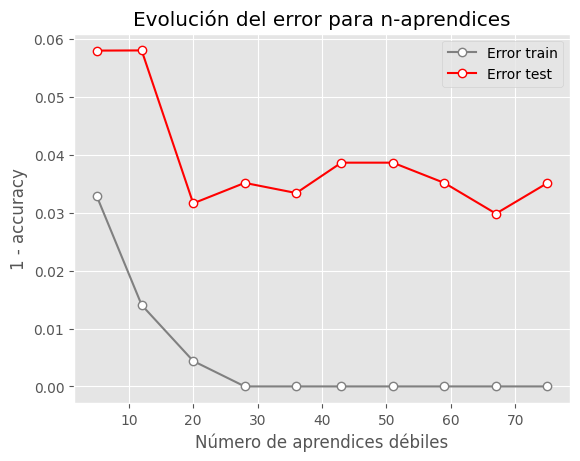

In [ ]:
plt.style.use('ggplot')
err_kfold_train = df_err_train.groupby(['nest'])['err'].mean()
err_kfold_test = df_err_test.groupby(['nest'])['err'].mean()

plt.title('Evolución del error para n-aprendices')
plt.plot(err_kfold_train.index, err_kfold_train, '-o', c='gray', mfc='white', label='Error train')
plt.plot(err_kfold_train.index, err_kfold_test, '-o', c='red', mfc='white', label='Error test')
plt.xlabel('Número de aprendices débiles')
plt.ylabel('1 - accuracy')
plt.grid(True)
plt.legend();


El gráfico sugiere que con  28 estimadores es suficiente para obtener un error acotado.

###Impacto en el error para hiper parámetro learning rate

La tasa de aprendizaje, cuando es alta, impacta en la ponderación que tendrán los aprendices débiles afectando especialmente cuando la muestra presenta valores atípicos. Esto se debe a que el ensemble hará crecer rápidamente esa observación lo que puede ocasionar un bajo rendimiento del modelo. Habitualmente se usa learning rate bajo, con el costo de que tengamos que usar más aprendices débiles y esto significa más tiempo para el entrenamiento.

Para encontrar un buen estimador de learning rate para los datos de cáncer de mama que hemos estado revisando, se usa validación cruzada con cinco fold, para una cantidad de estimadores fija igual a nueve.


In [ ]:

k_fold = 5
n_lrate = 15
lst_lrate = np.linspace(0.1, 1.0, n_lrate)
nest = 9

learner_base = DecisionTreeClassifier(max_depth=1)
df_err_test = pd.DataFrame({'lr':[], 'ifold':[], 'err':[]})
df_err_train = pd.DataFrame({'lr':[], 'ifold':[], 'err':[]})

skf = StratifiedKFold(n_splits=k_fold, shuffle=True)
for idx, lr in enumerate(lst_lrate):
    for ifold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
        X_train, X_test = X.loc[train_idx], X.loc[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        aboost_aux = AdaBoostClassifier(
            estimator=learner_base, n_estimators=nest, learning_rate=lr
        )

        aboost_aux.fit(X_train, y_train)

        yhat_test = aboost_aux.predict(X_test)
        yhat_train = aboost_aux.predict(X_train)

        err_ = 1 - accuracy_score(y_test, yhat_test)
        df_err_test = pd.concat([
            df_err_test, pd.DataFrame({'lr': [lr], 'ifold':[ifold], 'err': [err_]})
        ], axis=0)

        err_ = 1 - accuracy_score(y_train, yhat_train)
        df_err_train = pd.concat([
            df_err_train, pd.DataFrame({'lr': [lr], 'ifold':[ifold], 'err': [err_]})
        ], axis=0)


/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/usr/local/lib/python3.1

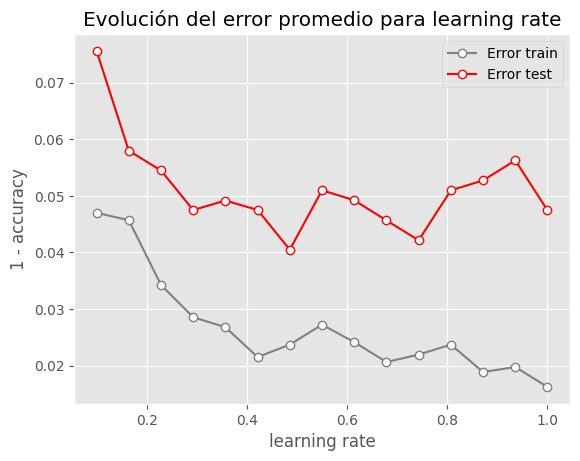

In [ ]:
plt.style.use('ggplot')
err_kfold_train = df_err_train.groupby(['lr'])['err'].mean()
err_kfold_test = df_err_test.groupby(['lr'])['err'].mean()

plt.title(r'Evolución del error promedio para learning rate')
plt.plot(err_kfold_train.index, err_kfold_train, '-o', c='gray', mfc='white', label='Error train')
plt.plot(err_kfold_train.index, err_kfold_test, '-o', c='red', mfc='white', label='Error test')
plt.xlabel('learning rate')
plt.ylabel('1 - accuracy')
plt.grid(True)
plt.legend();


En el plot se visualiza como a medida que vamos incrementando learning rate se obtienen errores promedio menores tanto en la muestra de entrenamiento como de test. Observamos además que, con learning_rate = 0.7 logramos un buen ajuste.

## El algoritmo descenso de gradiente

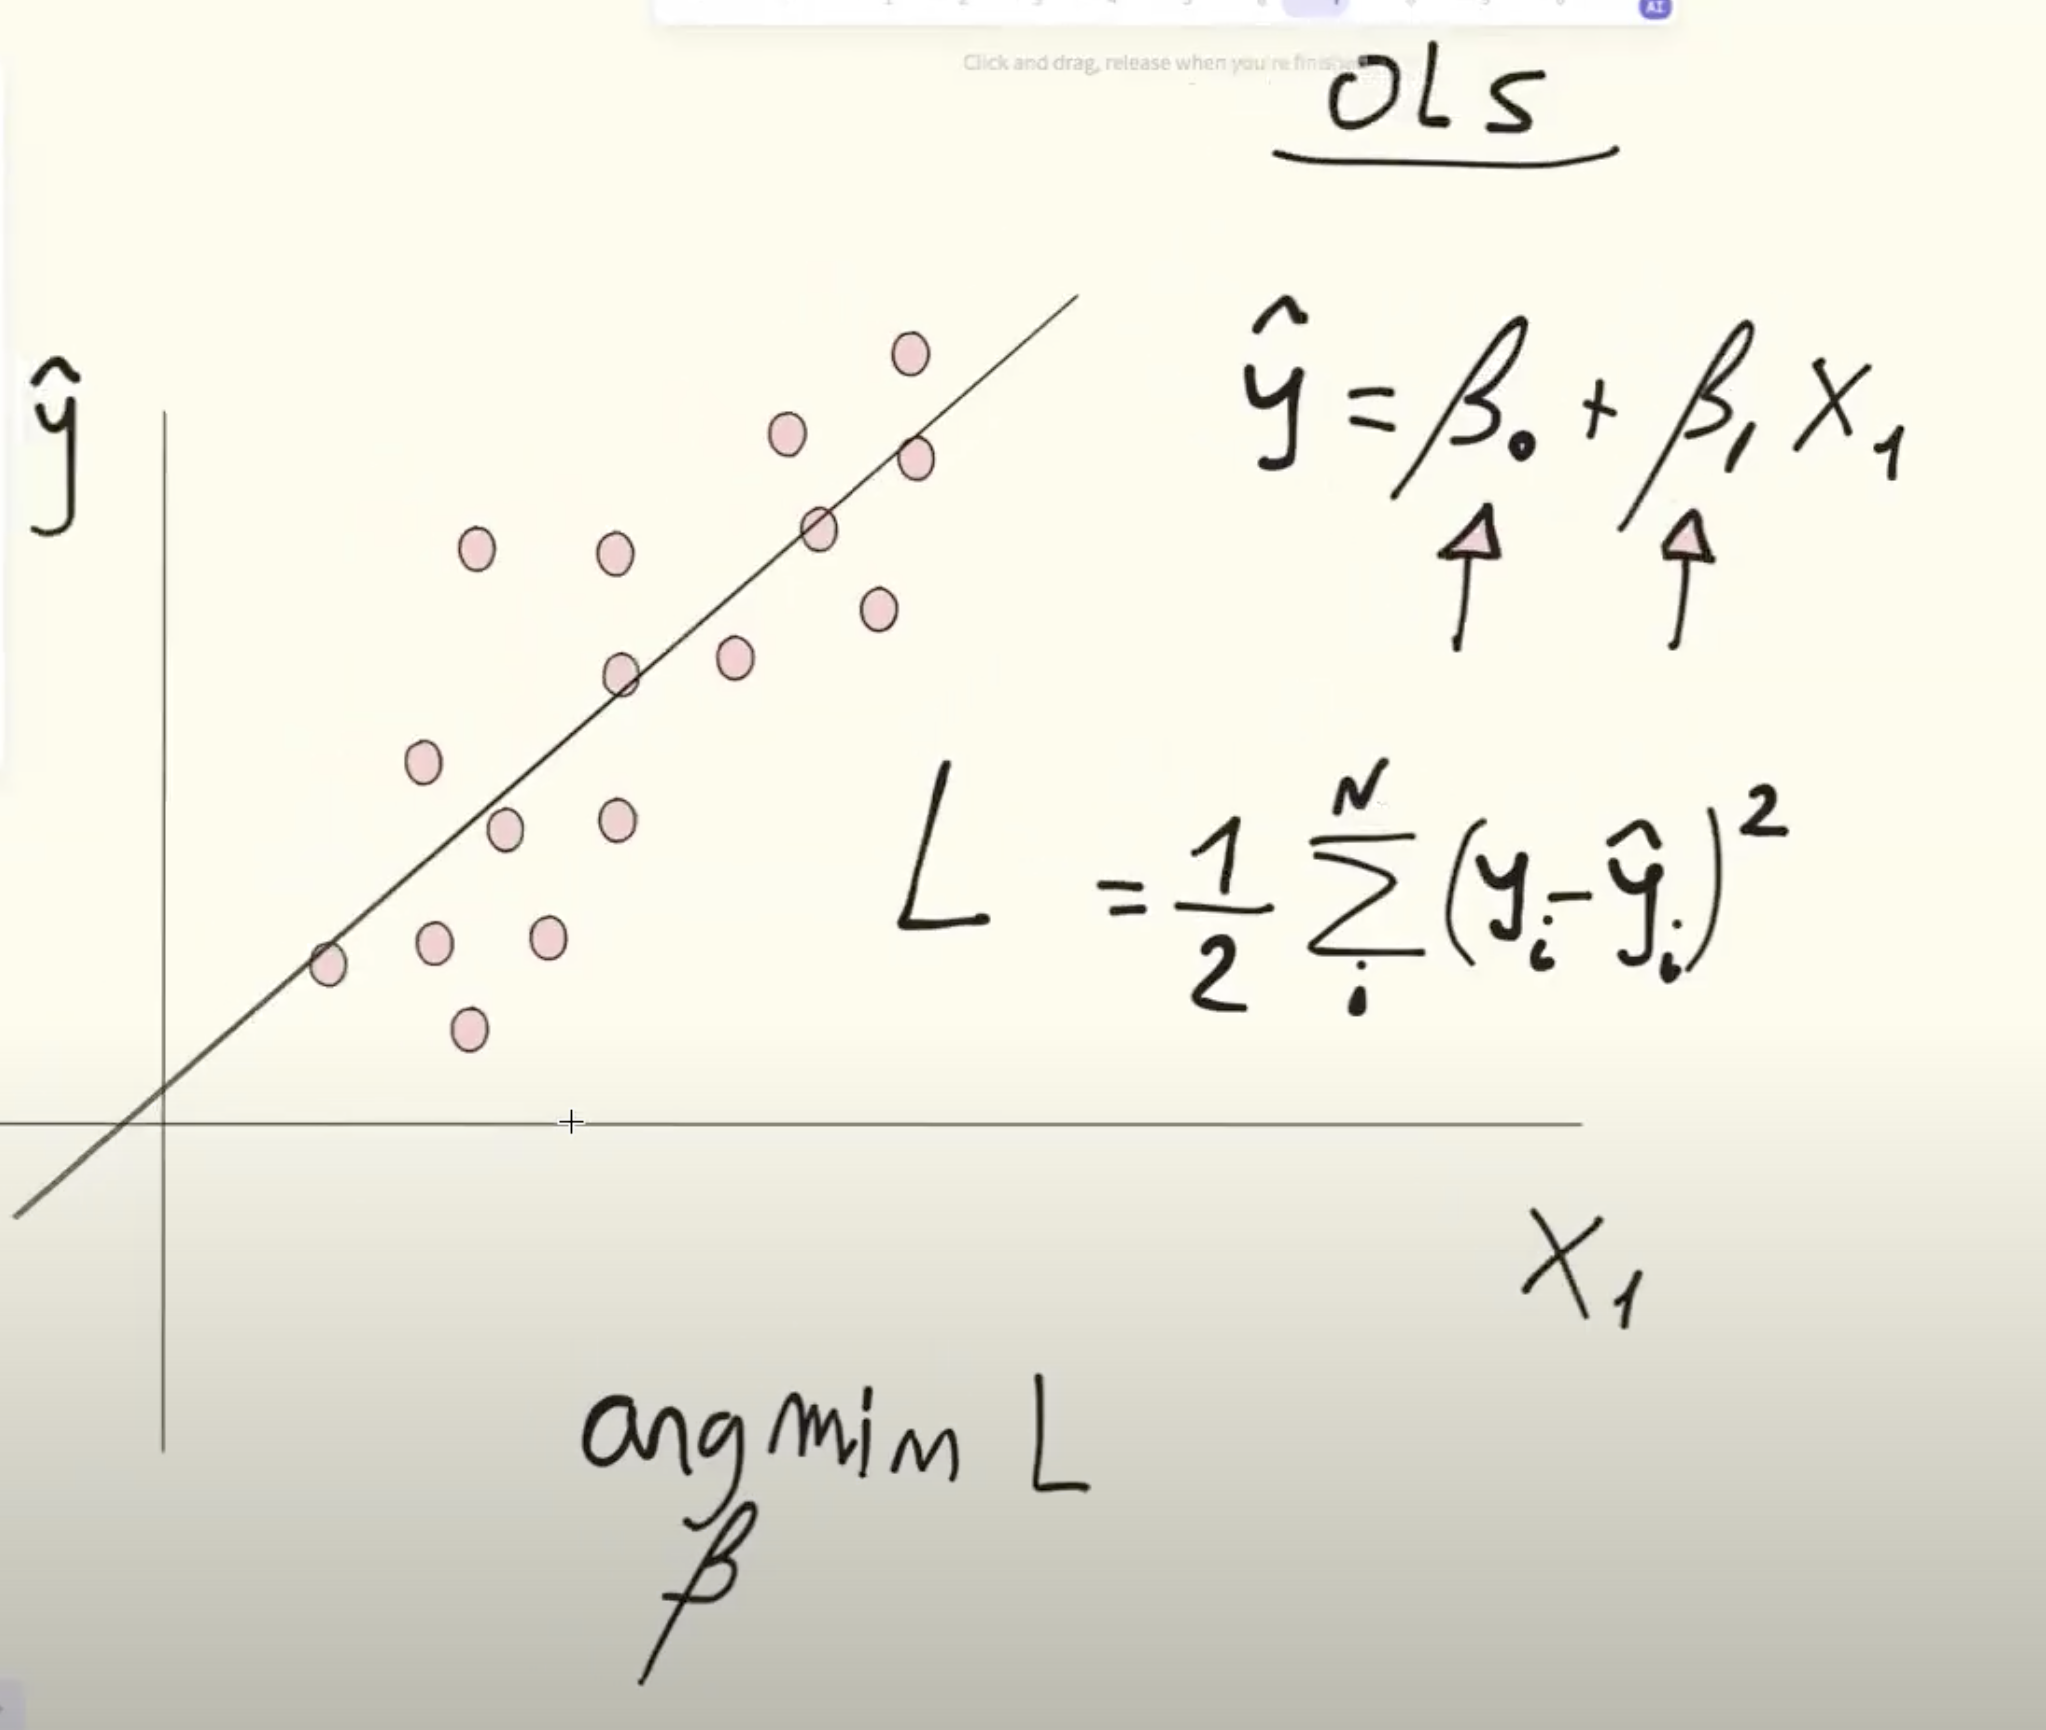

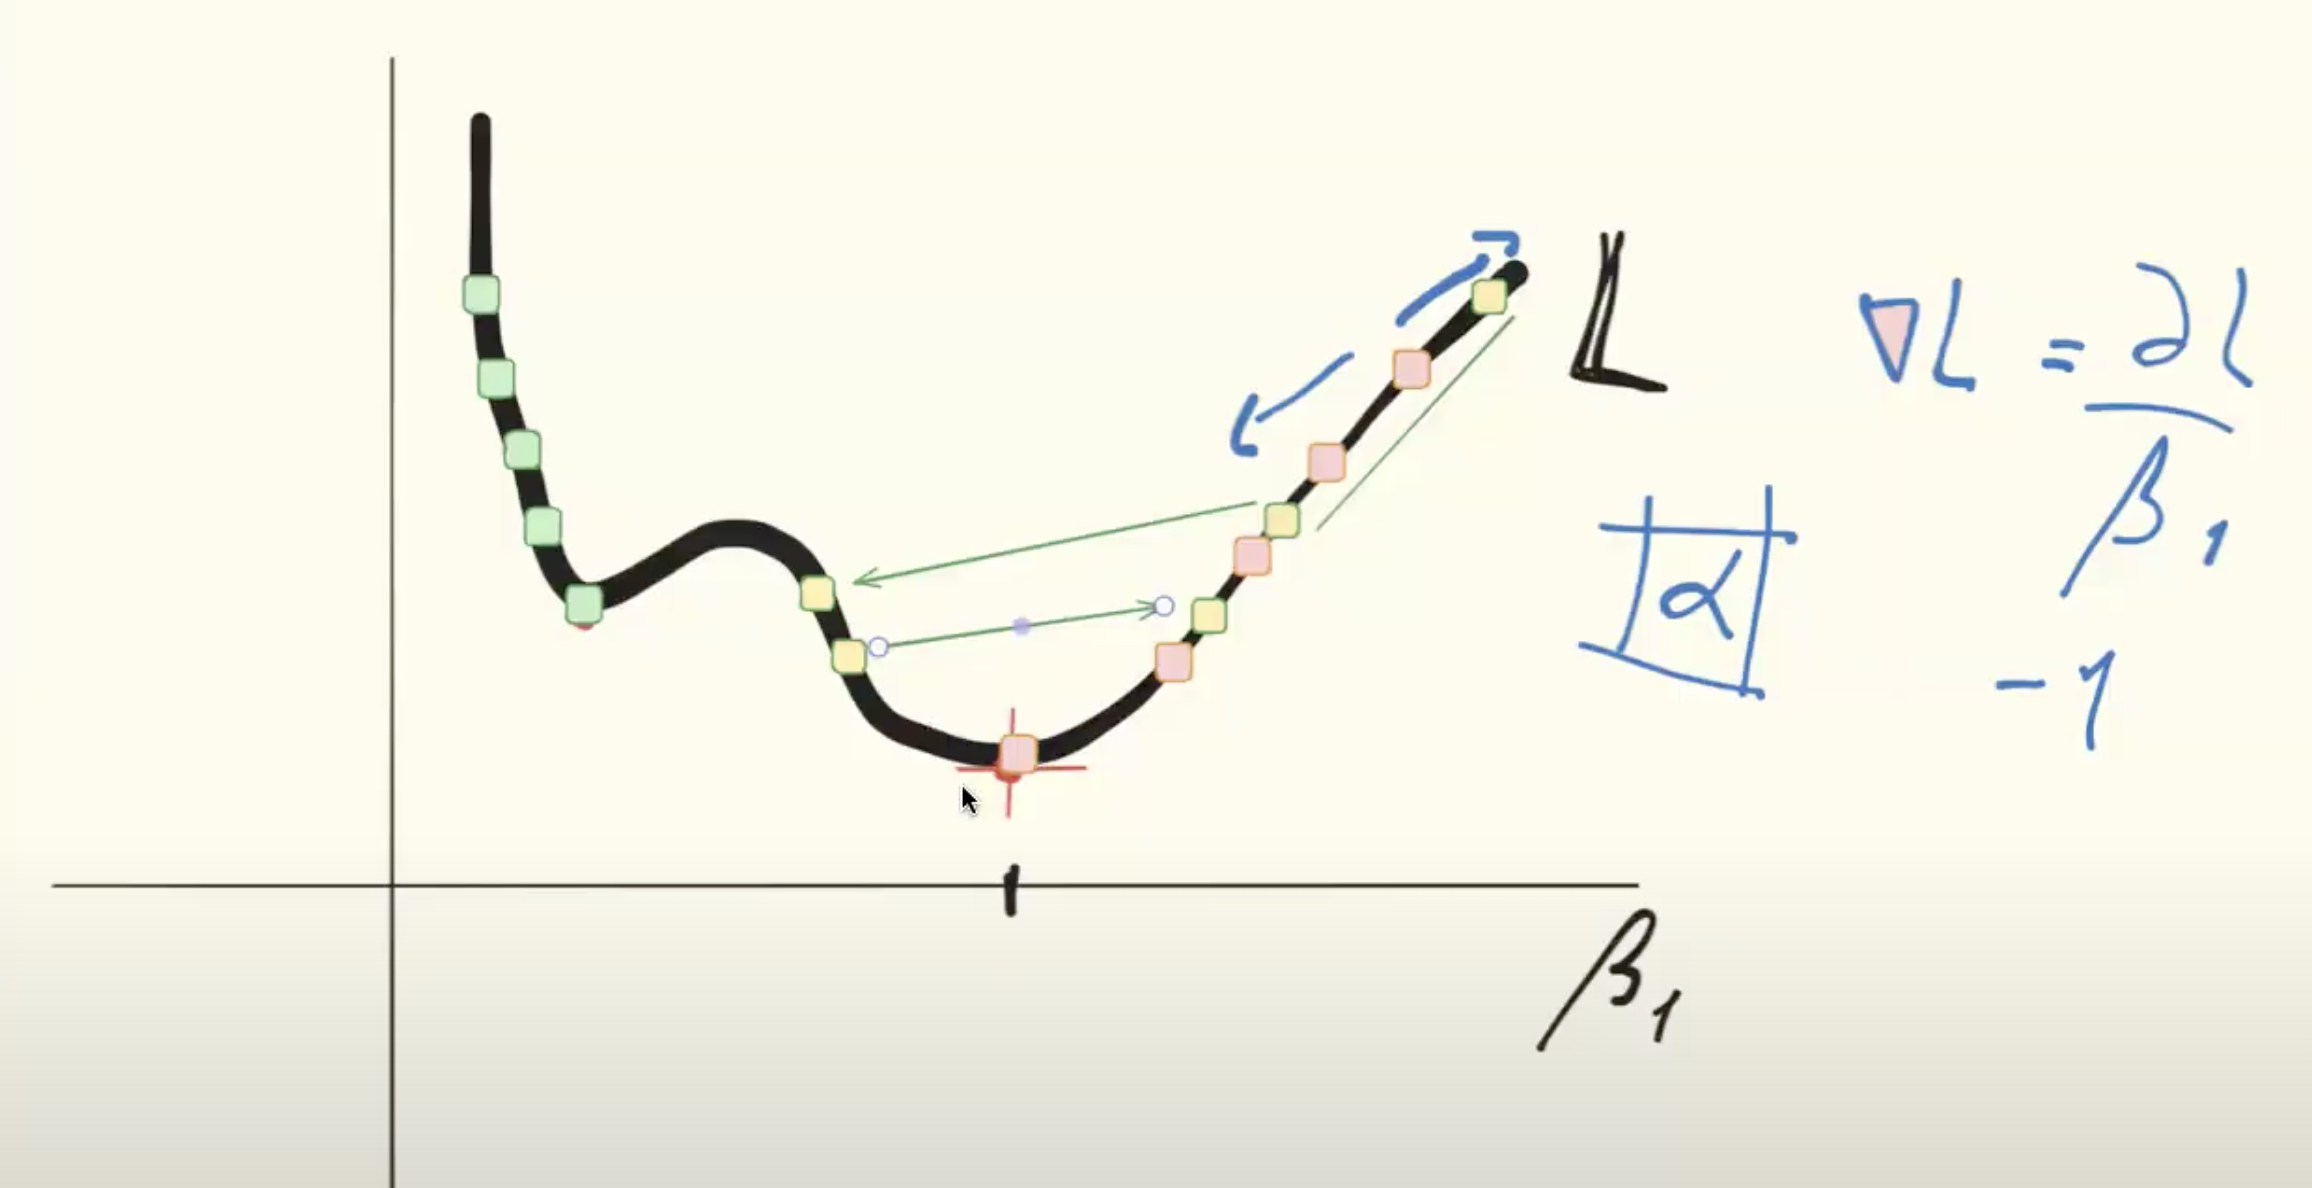

Tanto GBoost (Gradient Boosting) como XGBoost (Extreme Gradient Boosting) están relacionados con el algoritmo de **descenso de gradiente**. Aquí te explico cómo se conectan:

El descenso de gradiente es un algoritmo de optimización utilizado para minimizar funciones de pérdida. Funciona ajustando los parámetros del modelo en la dirección opuesta al gradiente de la función de pérdida.



##Gradient Boosting


GBoost, o "Gradient Boosting", es otro algoritmo de boosting que también combina modelos débiles, pero lo hace de manera diferente.

Utiliza el concepto de descenso de gradiente para minimizar la función de pérdida de un modelo al agregar nuevos modelos (árboles) que corrigen los errores de los modelos anteriores.
   - En cada iteración, se ajusta un nuevo árbol a los residuos (errores) de las predicciones actuales, utilizando el descenso de gradiente para determinar la dirección y el tamaño del ajuste.



Aquí te lo explico en pasos sencillos:

1. **Modelo inicial**: Comienza con un modelo simple que hace una predicción inicial (puede ser la media de las etiquetas, por ejemplo).

2. **Errores residuales**: Calcula los errores de predicción, que son las diferencias entre las predicciones actuales y las etiquetas reales.

3. **Modelo nuevo**: Crea un nuevo modelo débil (generalmente un árbol de decisión) que intenta predecir estos errores residuales.

4. **Ajuste**: Agrega este nuevo modelo a la predicción actual. La idea es corregir los errores del modelo anterior.

5. **Iterar**: Repite el proceso: calcula los nuevos errores residuales, entrena otro modelo débil sobre esos errores y ajusta la predicción.

6. **Combina modelos**: Al final, la predicción total es la suma de todas las predicciones de los modelos débiles, cada uno multiplicado por un coeficiente que controla su influencia.

La clave de Gradient Boosting es que se enfoca en minimizar el error de manera gradual, mejorando así la precisión del modelo en cada iteración. Es muy poderoso y se utiliza en muchas aplicaciones de machine learning.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# usamos el mismo conjunto de cancer de mama
# y también entrenaremos con los mismos segmentos que
# en adaptive boosting

gboost_m1 = GradientBoostingClassifier(learning_rate=0.01, n_estimators=40)
gboost_m1.fit(X_train, y_train)


GradientBoostingClassifier(learning_rate=0.01, n_estimators=40)

Realizamos predicciones con el modelo entrenado **gboost_m1** para los conjuntos de entrenamiento y test.

In [ ]:
# predicción con el modelo previamente entrenado
# para los segmentos de entrenamiento y test

yhat_train = gboost_m1.predict(X_train)
yhat_test = gboost_m1.predict(X_test)

# se calcula el error
err_test = np.round(1 - accuracy_score(y_test, yhat_test), 4)
err_train = np.round(1 - accuracy_score(y_train, yhat_train), 4)

print(f'[Error en train, Error en test]: [{err_train}, {err_test}]')


[Error en train, Error en test]: [0.0241, 0.0796]


Este resultado equivale a un error menor con respecto al error que obtuvimos con Adaptive Boosting para el conjunto de test.

Las métricas de matriz de confusión para los datos de test son:


In [ ]:
print('Métricas para datos de test')
print(classification_report(y_test, yhat_test))


Métricas para datos de test
              precision    recall  f1-score   support

           0       0.95      0.83      0.89        42
           1       0.91      0.97      0.94        71

    accuracy                           0.92       113
   macro avg       0.93      0.90      0.91       113
weighted avg       0.92      0.92      0.92       113



Se aprecia un buen rendimiento de f1-score.

Al revisar estos indicadores en el conjunto de entrenamiento luego de revisar los resultados en el conjunto de test, tenemos un alto rendimiento, como era de esperar.

In [ ]:
print('Métricas para datos de train')
print(classification_report(y_train, yhat_train))


Métricas para datos de train
              precision    recall  f1-score   support

           0       1.00      0.94      0.97       170
           1       0.96      1.00      0.98       286

    accuracy                           0.98       456
   macro avg       0.98      0.97      0.97       456
weighted avg       0.98      0.98      0.98       456



Si revisamos los hiper parámetros que usa el modelo de Gradient Boosting en sklearn, nos encontramos que por defecto entrena árboles de regresión con profundidad de 3. Ahora con respecto a la función de pérdida que utiliza este modelo en sklearn,  corresponde a **log_loss** que es la entropía cruzada.

Mostraremos cómo la función de pérdida va disminuyendo a medida que incorporamos más estimadores (árboles de regresión), medida en el conjunto de test.


In [ ]:
# Nos movemos en la función de pérdida en cada iteración
# para el conjunto de test
from sklearn.metrics import log_loss

tmp_loss_storage = np.empty(gboost_m1.n_estimators)

for idx, individual_estimate in enumerate(gboost_m1.staged_decision_function(X_test)):
    tmp_loss_storage[idx] = log_loss(y_test, individual_estimate)


Visualizamos ahora la curva de la función de pérdida para distinta cantidad de estimadores.

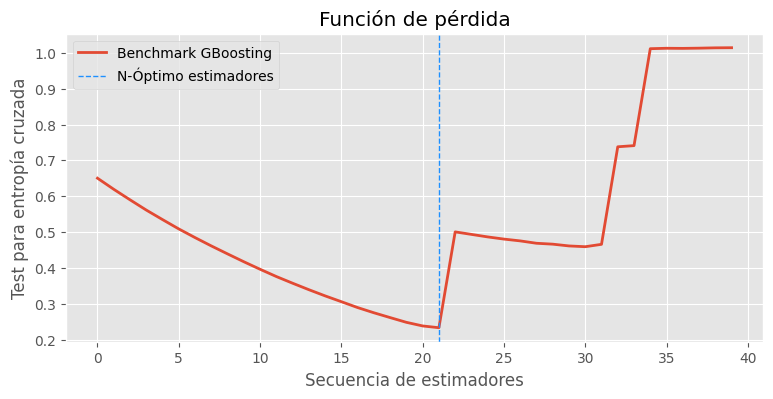

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tmp_loss_storage, label='Benchmark GBoosting', lw=2)
ax.axvline(x=np.argmin(tmp_loss_storage), lw=1, ls='--', color='dodgerblue', label='N-Óptimo estimadores')
ax.legend()
ax.set_title('Función de pérdida')
ax.set_xlabel('Secuencia de estimadores')
ax.set_ylabel('Test para entropía cruzada');



A medida que se incorporan más estimadores, la función de pérdida muestra una clara tendencia a ir disminuyendo. Esto no será así siempre. ya que habrá un punto en que crezca e incluso puede ir moviéndose creciendo y disminuyendo, lo que dependerá principalmente de la tasa de aprendizaje.


###Hiper parámetros en Gradient Boosting

Los principales hiper parámetros son:
*  Aquellos relacionados al aprendiz débil, que en este caso sklearn usa árboles de regresión.
*  Hiper parámetros asociados al funcionamiento del ensamble. Acá tenemos la tasa de aprendizaje y la proporción de observaciones a seleccionar para cada aprendiz débil
*  Aquellos relacionados a la parte funcional como la función de pérdida a emplear


###Tasa de aprendizaje

Este hiper parámetro regula cómo será el paso cada vez que nos movemos en la función de pérdida, por lo cual valores altos podrían converger rápido a un valor bajo en la función. Sin embargo, también puede provocar que estando cerca del mínimo no pueda alcanzarlo nunca. Por otro lado, una tasa de aprendizaje peqeño tendrá un entrenamiento lento pero podrá alcanzar un mínimo.

Entrenamos Gradient Boosting para 150 estimadores con tasas de aprendizaje que van de 0.01 a 1.5, para las cuales se calcula su función de pérdida para cada estimador.


In [ ]:
lst_lr = [0.01, 0.05, 0.1, 0.5, 1.0, 1.5]
tmp_loss_storage_lr = []

for i, lr in enumerate(lst_lr):
    gboost_m1_aux = GradientBoostingClassifier(random_state=23, learning_rate=lr, n_estimators=150)
    gboost_m1_aux.fit(X_train, y_train)

    tmp_loss_storage = np.empty(gboost_m1_aux.n_estimators)

    for idx, individual_estimate in enumerate(gboost_m1_aux.staged_decision_function(X_test)):
        tmp_loss_storage[idx] = log_loss(y_test, individual_estimate)

    tmp_loss_storage_lr.append(tmp_loss_storage)


Se grafican los resultados, en los que se observa que cuando la tasa es baja la función de pérdida llega a los mínimos de manera más lenta, y cuando la tasa es alta ocurre que a veces no llega a los mínimos y su descenso es más rápido. Además, se produce un aumento en la pérdida (en este ejemplo, para la tasa de aprendizaje 1.5). En consecuencia, es importante poder sintonizar este valor para lograr un buen rendimiento en el modelo.


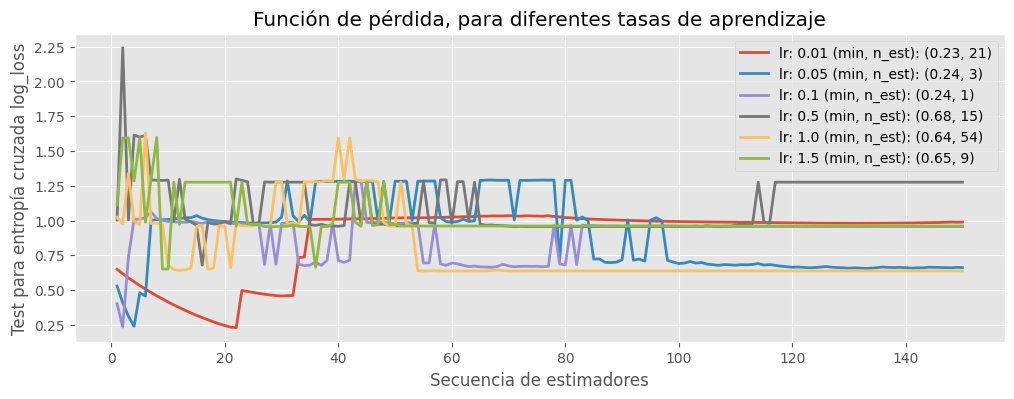

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.set_title('Función de pérdida, para diferentes tasas de aprendizaje')
ax.set_xlabel('Secuencia de estimadores')
ax.set_ylabel('Test para entropía cruzada log_loss');

for i, loss_storage in enumerate(tmp_loss_storage_lr):
    lr = lst_lr[i]

    mmin = np.round(np.min(loss_storage), 2)
    n_est = np.argmin(loss_storage)
    ax.plot(range(1, len(loss_storage)+1),loss_storage, label=f'lr: {lr} (min, n_est): ({mmin}, {n_est})', lw=2)

ax.legend();


####Subsample

Este hiper parámetro controla la proporción de observaciones que se escogen aleatoriamente en cada árbol de regresión en la secuencia, mientras más pequeño sea este, se logra disminuir la varianza del modelo y con esto elevar el nivel de generalización.


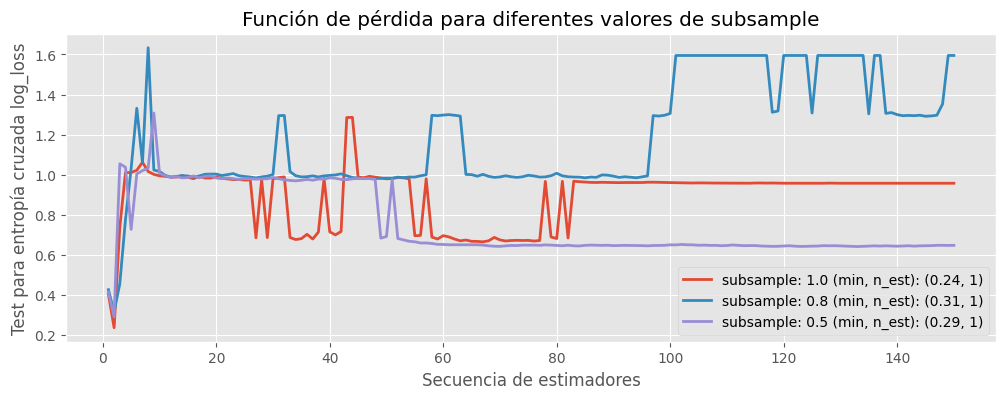

In [ ]:
'''
Esto no estaba en el documento, hice lo que me pareció (usando Chat GPT)

'''

lst_subsample = [1.0, 0.8, 0.5]  # Diferentes valores de subsample
tmp_loss_storage_subsample = []

for i, subsample in enumerate(lst_subsample):
    gboost_m1_aux = GradientBoostingClassifier(random_state=23, subsample=subsample, n_estimators=150)
    gboost_m1_aux.fit(X_train, y_train)

    tmp_loss_storage = np.empty(gboost_m1_aux.n_estimators)

    for idx, individual_estimate in enumerate(gboost_m1_aux.staged_decision_function(X_test)):
        tmp_loss_storage[idx] = log_loss(y_test, individual_estimate)

    tmp_loss_storage_subsample.append(tmp_loss_storage)

fig, ax = plt.subplots(figsize=(12, 4))

ax.set_title('Función de pérdida para diferentes valores de subsample')
ax.set_xlabel('Secuencia de estimadores')
ax.set_ylabel('Test para entropía cruzada log_loss')

for i, loss_storage in enumerate(tmp_loss_storage_subsample):
    subsample = lst_subsample[i]

    mmin = np.round(np.min(loss_storage), 2)
    n_est = np.argmin(loss_storage)
    ax.plot(range(1, len(loss_storage) + 1), loss_storage, label=f'subsample: {subsample} (min, n_est): ({mmin}, {n_est})', lw=2)

ax.legend()

En el gráfico vemos que usando subsample = 100% se logra el menor valor para la función de pérdida, este valor es el usado por defecto en sklearn.

Ahora debemos considerar cual es la mejor combinación de hiper parámetros que nos lleve al mejor ajuste, para ello usaremos búsqueda por grilla con los siguientes valores:

<center><strong>n_estimators: </strong> 20, 50, 80, 120</center>
<center><strong>learning_rate: </strong> 0.01, 0.05, 0.1, 0.5, 1.0, 3.0</center>
<center><strong>subsample: </strong> 2np.linspace(0.05, 1, 5)</center>

Se entrena el modelo en búsqueda de los hiper parámetros óptimos, usando cinco fold para validación cruzada.

In [ ]:
%%time
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [20, 50, 80, 120],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0, 3.0],
    'subsample': np.linspace(0.05, 1, 5)
}

gboost_m1_grid = GridSearchCV(GradientBoostingClassifier(), param_grid=param_grid, cv=5, n_jobs=-1)
gboost_m1_grid.fit(X_train, y_train)


CPU times: user 3.28 s, sys: 261 ms, total: 3.54 s
Wall time: 2min 36s


GridSearchCV(cv=5, estimator=GradientBoostingClassifier(), n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0, 3.0],
                         'n_estimators': [20, 50, 80, 120],
                         'subsample': array([0.05  , 0.2875, 0.525 , 0.7625, 1.    ])})

In [ ]:
print('Mejores hiper parámetros encontrados')
print(gboost_m1_grid.best_params_)
print()
print('Mejor score alcanzado:')
print(gboost_m1_grid.best_score_)


Mejores hiper parámetros encontrados
{'learning_rate': 0.5, 'n_estimators': 80, 'subsample': 0.7625}

Mejor score alcanzado:
0.9693502150023889


Entrenamos un modelo usando los hiper parámetros óptimos encontrados anteriormente:

In [ ]:
yhat = gboost_m1_grid.best_estimator_.predict(X_test)
print(classification_report(y_test, yhat))


              precision    recall  f1-score   support

           0       0.97      0.93      0.95        42
           1       0.96      0.99      0.97        71

    accuracy                           0.96       113
   macro avg       0.97      0.96      0.96       113
weighted avg       0.96      0.96      0.96       113



Podemos observar que se logra un muy alto rendimiento para el conjunto de test.

Más abajo se muestra este rendimiento en la curva ROC junto con el rendimiento en el segmento de entrenamiento.

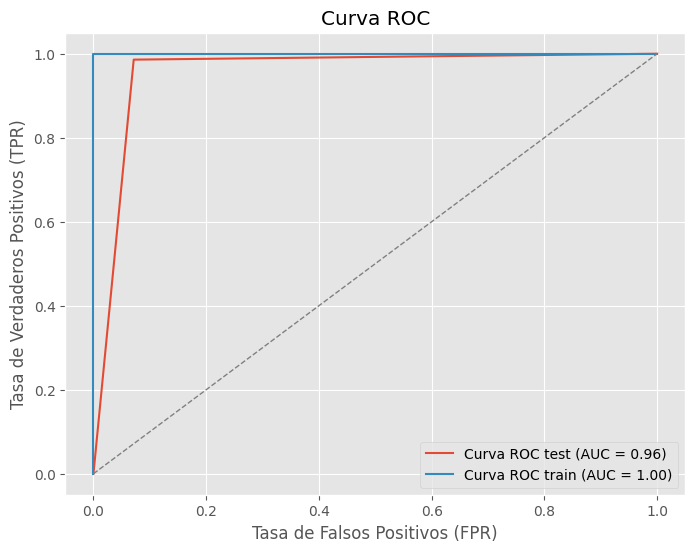

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

yhat_test_proba = gboost_m1_grid.best_estimator_.predict(X_test)
yhat_train_proba = gboost_m1_grid.best_estimator_.predict(X_train)

# Calcular la tasa de verdaderos positivos (TPR) y la tasa de falsos positivos (FPR)
fpr_test, tpr_test, umbrales_test = roc_curve(y_test, yhat_test_proba)
fpr_train, tpr_train, umbrales_train = roc_curve(y_train, yhat_train_proba)

# Calcular el área bajo la curva ROC (AUC)
auc_test = roc_auc_score(y_test, yhat_test_proba)
auc_train = roc_auc_score(y_train, yhat_train_proba)

# Plot de la curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr_test, tpr_test, lw=1.5, label='Curva ROC test (AUC = {:.2f})'.format(auc_test))
plt.plot(fpr_train, tpr_train, lw=1.5, label='Curva ROC train (AUC = {:.2f})'.format(auc_train))

plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1)
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.show();


## XGboost


XGBoost, que significa "Extreme Gradient Boosting", es una variante de Gradient Boosting que está diseñada para ser más eficiente y efectiva.

- XGBoost mejora el método original de Gradient Boosting al introducir técnicas más sofisticadas de optimización. Utiliza un enfoque de descenso de gradiente, pero también implementa regularización y optimización paralela, lo que lo hace más eficiente.
   - En XGBoost, se puede definir una función de pérdida más compleja y se utilizan aproximaciones para calcular el gradiente y el hessiano (segunda derivada), lo que permite una actualización más rápida y precisa de los árboles.

Aquí te lo explico en pasos sencillos:

1. **Modelo inicial**: Comienza con un modelo simple para hacer una predicción inicial.

2. **Errores residuales**: Calcula los errores (residuos) de la predicción actual.

3. **Modelo nuevo**: Crea un nuevo árbol de decisión que intenta predecir estos errores. XGBoost utiliza técnicas avanzadas para optimizar este proceso, como la regularización para evitar el sobreajuste.

4. **Regularización**: Introduce términos de regularización en la función de pérdida para controlar la complejidad del modelo, lo que ayuda a mejorar la generalización.

5. **Actualización ponderada**: Al agregar el nuevo modelo, ajusta las predicciones de manera que cada árbol se enfoque en corregir los errores de los anteriores.

6. **Paralelización**: A diferencia de otros algoritmos de boosting, XGBoost puede construir árboles en paralelo, lo que acelera considerablemente el entrenamiento.

7. **Predicción final**: La predicción total es la suma de todas las predicciones de los árboles, ajustadas por sus respectivos coeficientes.

XGBoost es muy popular por su rapidez y precisión, y se ha utilizado con éxito en muchas competiciones de machine learning. Su capacidad para manejar grandes conjuntos de datos y su flexibilidad lo hacen una opción preferida para muchos problemas.


La creación del modelo, su entrenamiento y predicción siguen la misma estructura que en sklearn. Será necesario antes instalar esta biblioteca.

In [ ]:
pip install XGBoost

In [ ]:
%%time
import xgboost as xgb

param_grid = {
    'n_estimators': [20, 50, 80, 120],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0, 3.0],
    'subsample': np.linspace(0.05, 1, 5)
}

xgboost_m1_grid = GridSearchCV(xgb.XGBClassifier(random_state=23, max_depth=4), param_grid=param_grid, cv=5, n_jobs=-1)
xgboost_m1_grid.fit(X_train, y_train)


CPU times: user 3.94 s, sys: 233 ms, total: 4.17 s
Wall time: 1min 49s


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None,...
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=4,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None,
                                     random_state=23, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0, 3.0],
                         'n_estimators': [20, 50, 80, 120],
                         'subsample': array([0.05  , 0.2875, 0.525 , 0.7625, 1.    ])})

In [ ]:
print('Mejores hiper parámetros encontrados')
print(xgboost_m1_grid.best_params_)
print()
print('Mejor score alcanzado:')
print(xgboost_m1_grid.best_score_)


Mejores hiper parámetros encontrados
{'learning_rate': 0.5, 'n_estimators': 80, 'subsample': 0.7625}

Mejor score alcanzado:
0.9671524128045867


Las métricas para la matriz de confusión son:

In [ ]:
yhat = xgboost_m1_grid.best_estimator_.predict(X_test)
print(classification_report(y_test, yhat))


              precision    recall  f1-score   support

           0       1.00      0.95      0.98        42
           1       0.97      1.00      0.99        71

    accuracy                           0.98       113
   macro avg       0.99      0.98      0.98       113
weighted avg       0.98      0.98      0.98       113



Con XGBoost se logra una pequeña mejora en la predicción del conjunto de entrenamiento en Gradient Boosting era de 0.98 y en XGBoost 0.99.